# 12 팀 모델 B 안정화: 에폭 수, 학습률 스케줄, 가중치 평균(EMA)

지금 팀 모델 B(E13: 로그 멜 CNN, "명령 아님" 전부로 학습 79,392개, 20에폭, Adam 학습률 1e-3 고정)는 08에서 마지막 5에폭 검증 F1이 0.8985 ± 0.0229였고, 에폭 사이에 F1이 0.71까지 떨어지는 에폭이 있었습니다. 최고 에폭도 13~17이라 20에폭 안에서 수렴했는지 확실하지 않습니다. 여기서는 **한 번에 하나씩** 바꿔 흔들림을 줄입니다.

| 번호 | 바꾸는 것 | 비교 상대 | 확인하려는 것 |
|---|---|---|---|
| E13r | 없음 (E13 다시 실행: 20에폭, 학습률 고정) | 08의 E13 | 같은 코드에서 기준값 |
| E27 | 에폭 20 → **40** (학습률 고정) | E13r | 더 학습하면 좋아지는가, 과적합(검증 손실 상승)이 생기는가 |
| E28 | E27 + **코사인 학습률** (1e-3에서 40에폭 동안 0으로 줄임) | E27 | 학습률을 줄이면 끝 무렵 흔들림이 줄어드는가 |
| E29 | E27 + **가중치 평균(EMA, 감쇠 0.999)** 으로 평가 | E27 | 에폭 사이 흔들림이 평균으로 줄어드는가 |

- 구조, 배치 256, 데이터, 검증 묶음은 모두 같습니다. 시드 2개.
- 지표: 최고 에폭(검증 매크로 F1 기준)의 결과, **마지막 에폭의 결과**, 마지막 5에폭 F1의 평균 ± 표준편차, 검증 손실. 안정적이라면 최고 에폭과 마지막 에폭이 비슷해야 합니다.
- 도구: `torch.optim.lr_scheduler.CosineAnnealingLR`, `torch.optim.swa_utils.AveragedModel`(+ `get_ema_multi_avg_fn`).
- 학습마다 진행 상황을 출력합니다. 예상 시간: 20에폭 약 2.6분 × 2 + 40에폭 약 5.1분 × 6 ≈ 36분(08 실측 에폭당 7.7초 기준 어림).
- 시험 묶음은 쓰지 않습니다. 처음 듣는 단어 흉내(4묶음)는 최종 설정을 고른 뒤에 따로 확인합니다.

In [6]:
# 셀 1. 설정과 버전
import os, sys, time, random, copy, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
import matplotlib.pyplot as plt

SMOKE = False                  # True: 단어마다 몇 개만, 짧게 (결과 숫자는 쓰지 않음)
USE_DRIVE = False              # True: Colab에서 Google Drive를 연결해 스펙트로그램을 Drive에 저장·재사용 (10·11에서 저장한 것 사용)
SEEDS = [0, 1]
RUNS_SPEC = {                  # 번호: (에폭, 학습률 스케줄, EMA)
    "E13r": (20, "고정", False),
    "E27": (40, "고정", False),
    "E28": (40, "코사인", False),
    "E29": (40, "고정", True),
}
EMA_DECAY = 0.999
CONDS = {"E15": 153, "E16": None}   # 셀 2(09와 같은 코드)가 출력에 씀
FOLD_SEED = 0
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
AUX = ["bed", "bird", "cat", "dog", "happy", "house", "marvin", "sheila", "tree", "wow"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
B_EPOCHS, B_LR, B_BATCH = 20, 1e-3, 256          # 09와 같음 (에폭은 실험마다 RUNS_SPEC으로 바꿈)
B_CHANNELS = [16, 32, 64, 128]

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
if SMOKE:
    CONDS = {"E15": 3, "E16": None}
    RUNS_SPEC = {k: (max(2, e // 10), s, m) for k, (e, s, m) in RUNS_SPEC.items()}
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR)

python 3.13.16 | torch 2.11.0+cu130 | torchaudio 2.11.0+cu130 | pandas 2.3.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 cache


In [7]:
# 셀 2. 데이터 (08·09와 같은 구성. 4묶음은 여기서 쓰지 않음)
os.makedirs(DATA_ROOT, exist_ok=True)
sc = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")    # 공식 학습 목록 (검증·시험 목록 제외)
BASE_DIR = os.path.dirname(sc._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 쓰지 않음
base_train = table[table.split == "train"]

rows = []
for i in range(len(sc)):
    path, _, word, spk, _ = sc.get_metadata(i)
    if word in COMMANDS or word in UNSEEN:
        continue
    rows.append({"split": "train", "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                 "label": OTHER, "group": "seen_other", "start": 0, "gain": 1.0})
pool = pd.DataFrame(rows)
assert sorted(pool.word.unique()) == sorted(DIGITS + AUX)
used = set(base_train[base_train.group == "seen_other"].path)
assert used <= set(pool.path)
rng = np.random.default_rng(0)
pool["first"] = ~pool.path.isin(used)                        # 08과 같은 순서: 07에서 쓴 153개가 먼저
pool["rnd"] = rng.random(len(pool))
pool = pool.sort_values(["word", "first", "rnd"]).drop(columns=["first", "rnd"])
pool["rank"] = pool.groupby("word").cumcount()

rest = base_train[base_train.group != "seen_other"].assign(rank=-1)
if SMOKE:
    rest = rest.groupby("label").head(10)
    pool = pool[pool["rank"] < 20]
train_all = pd.concat([rest, pool], ignore_index=True)
val = table[table.split == "val"].reset_index(drop=True)
if SMOKE:
    val = val.groupby(["label", "group", "word"], group_keys=False).sample(frac=1.0, random_state=0)
    val = val.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
L2I = {l: i for i, l in enumerate(LABELS)}
Y_ALL = torch.tensor(train_all.label.map(L2I).values)
Y_VAL = torch.tensor(val.label.map(L2I).values)
TRAIN_WORD = train_all.word.to_numpy(copy=True)
VAL_WORD = val.word.to_numpy(copy=True)

# 단어 4묶음: 숫자 3·3·2·2개 + 보조 단어 2·2·3·3개
fr = np.random.default_rng(FOLD_SEED)
d, a = list(fr.permutation(DIGITS)), list(fr.permutation(AUX))
FOLDS, i_d, i_a = [], 0, 0
for nd, na in [(3, 2), (3, 2), (2, 3), (2, 3)]:
    FOLDS.append([str(w) for w in sorted(d[i_d:i_d + nd]) + sorted(a[i_a:i_a + na])])
    i_d += nd; i_a += na
assert sorted(sum(FOLDS, [])) == sorted(DIGITS + AUX)

def train_mask(n, held):
    keep_n = (train_all.group != "seen_other") | (n is None) | (train_all["rank"] < (n or 0))
    return (keep_n & ~train_all.word.isin(held)).to_numpy(copy=True)

for f, held in enumerate(FOLDS):
    print(f"묶음 {f + 1}: 학습에서 뺄 단어 {held}")
    for eid, n in CONDS.items():
        m = train_mask(n, held)
        k = int((Y_ALL[torch.from_numpy(m)] == L2I[OTHER]).sum())
        print(f"   {eid} (단어마다 {n if n else '전부'}): 학습 {m.sum():,}개, '명령 아님' {k:,}개 ({k / m.sum():.1%}), "
              f"검증에서 뺀 단어 {np.isin(VAL_WORD, held).sum():,}개")

묶음 1: 학습에서 뺄 단어 ['four', 'six', 'two', 'cat', 'wow']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,469개
   E16 (단어마다 전부): 학습 66,857개, '명령 아님' 36,088개 (54.0%), 검증에서 뺀 단어 1,469개
묶음 2: 학습에서 뺄 단어 ['five', 'seven', 'three', 'dog', 'marvin']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,502개
   E16 (단어마다 전부): 학습 66,560개, '명령 아님' 35,791개 (53.8%), 검증에서 뺀 단어 1,502개
묶음 3: 학습에서 뺄 단어 ['nine', 'zero', 'bed', 'happy', 'tree']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,331개
   E16 (단어마다 전부): 학습 68,339개, '명령 아님' 37,570개 (55.0%), 검증에서 뺀 단어 1,331개
묶음 4: 학습에서 뺄 단어 ['eight', 'one', 'bird', 'house', 'sheila']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,278개
   E16 (단어마다 전부): 학습 68,189개, '명령 아님' 37,420개 (54.9%), 검증에서 뺀 단어 1,278개


In [8]:
# 셀 3. 소리 읽기 → 로그 멜 (07·08과 같은 설정, 저장해 두고 다시 씀)
def load_row(r):
    """06 노트북과 같은 규칙: 잡음은 start부터 1초를 잘라 gain을 곱함, 단어는 1초로 맞춤"""
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def cached(name, fn):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"  {name}: 저장된 것 사용 (처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)

def spec(df, name):
    def run():
        M, t0 = [], time.time()
        dl = torch.utils.data.DataLoader(Rows(df), batch_size=256, shuffle=False,
                                         num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))
        with torch.no_grad():
            for x in dl:
                M.append(to_db(mel(torch.from_numpy(x).to(device))).half().cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "sec": time.time() - t0}
        print(f"  {name}: 로그 멜 {tuple(d['mel'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

MEL_ALL = spec(train_all, "spec08_train_pool")["mel"]           # 08과 같은 이름·순서 → 저장된 게 있으면 다시 씀
MEL_VAL = spec(val, "spec09_val" if SMOKE else "spec11_val")["mel"]
assert len(MEL_ALL) == len(train_all) and len(MEL_VAL) == len(val)

  spec08_train_pool: 저장된 것 사용 (처음 계산 27초)
  spec11_val: 저장된 것 사용 (처음 계산 3초)


In [9]:
# 셀 4. 평가 함수와 팀 모델 B (08과 같은 CNN·학습, 에폭 선택만 뺀 단어 제외)
def evaluate(pred, held):
    """held: 학습에서 뺀 단어. 지표를 뺀 단어 / 남은 단어 / 잡음으로 나눠 계산"""
    p, t = pred.cpu().numpy(), Y_VAL.numpy()
    oth = L2I[OTHER]
    is_held = np.isin(VAL_WORD, held)
    sel = ~is_held                                           # 에폭 선택용: 뺀 단어 제외
    cm = np.bincount(t[sel] * K + p[sel], minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    is_cmd = t != oth
    known = (val.group.values == "seen_other") & ~is_held
    noise = val.group.values == "noise"
    return {"f1": float(f1.mean()), "acc": float(tp.sum() / cm.sum()),
            "fa_held": float(np.mean(p[is_held] != oth)) if is_held.any() else float("nan"),
            "fa_known": float(np.mean(p[known] != oth)),
            "fa_noise": float(np.mean(p[noise] != oth)) if noise.any() else float("nan"),
            "miss": float(np.mean(p[is_cmd] == oth)),
            "confuse": float(np.mean((p[is_cmd] != oth) & (p[is_cmd] != t[is_cmd]))),
            "pred": p}

class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))

def train_cnn(mask, seed, held):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scaler = torch.amp.GradScaler(enabled=AMP)
    best, hist, t_start = None, [], time.time()
    for ep in range(B_EPOCHS):
        cnn.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(idx)
        cnn.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            pred = torch.cat([cnn(Xva[i:i + 1024]).argmax(1) for i in range(0, len(Xva), 1024)])
        r = evaluate(pred, held)
        hist.append({"loss": tot / len(Xtr), "f1": r["f1"], "fa_held": r["fa_held"], "fa_known": r["fa_known"], "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    best["sec"] = time.time() - t_start
    return best, pd.DataFrame(hist)

In [10]:
# 셀 5. 학습 함수: 에폭 수, 학습률 스케줄(고정/코사인), EMA를 고를 수 있게. 에폭마다 검증 지표와 검증 손실을 남기고 진행 상황을 출력
MASK_ALL = train_mask(None, [])                 # "명령 아님" 전부 = 08의 E13과 같은 학습 데이터

def run_eval(model, Xva):
    model.eval()
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
        logits = torch.cat([model(Xva[i:i + 1024]) for i in range(0, len(Xva), 1024)]).float()
    loss = nn.functional.cross_entropy(logits, Y_VAL.to(device)).item()
    return logits.argmax(1), loss

def train_b(seed, epochs, sched, ema, tag):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(MASK_ALL)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if sched == "코사인" else None
    ema_model = AveragedModel(cnn, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True) if ema else None
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, best, t_start = [], None, time.time()
    for ep in range(epochs):
        cnn.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if ema_model is not None:
                ema_model.update_parameters(cnn)
            tot += loss.item() * len(idx)
        lr_now = opt.param_groups[0]["lr"]
        if scheduler is not None:
            scheduler.step()
        pred, vloss = run_eval(ema_model if ema_model is not None else cnn, Xva)
        r = evaluate(pred, [])
        hist.append({"epoch": ep + 1, "train_loss": tot / len(Xtr), "val_loss": vloss, "f1": r["f1"], "acc": r["acc"],
                     "fa": r["fa_known"], "miss": r["miss"], "lr": lr_now, "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
        if (ep + 1) % 5 == 0 or ep + 1 == epochs:
            print(f"    [{tag} 시드 {seed}] 에폭 {ep + 1:2d}/{epochs} | 학습 손실 {tot / len(Xtr):.4f} | 검증 손실 {vloss:.4f} | 검증 F1 {r['f1']:.4f} | "
                  f"오작동 {r['fa_known']:.3f} 놓침 {r['miss']:.3f} | 학습률 {lr_now:.2e} | {time.time() - t_start:.0f}초 경과")
    last = {**r, "epoch": epochs}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    return best, last, pd.DataFrame(hist)

In [11]:
# 셀 6. 학습: 실험 4개 × 시드 2개 (매번 처음부터)
RUNS = []
t_all = time.time()
for eid, (epochs, sched, ema) in RUNS_SPEC.items():
    for seed in SEEDS:
        print(f"{eid}: {epochs}에폭, 학습률 {sched}, EMA {'있음' if ema else '없음'}, 시드 {seed} 시작 (전체 {time.time() - t_all:.0f}초 경과)")
        best, last, h = train_b(seed, epochs, sched, ema, eid)
        late = h.iloc[-5:]
        RUNS.append({"번호": eid, "에폭": epochs, "학습률": sched, "EMA": "있음" if ema else "없음", "시드": seed,
                     "best": best, "last": last, "hist": h,
                     "최고 에폭": best["epoch"], "최고 F1": best["f1"], "마지막 F1": last["f1"],
                     "마지막5 평균": late.f1.mean(), "마지막5 표준편차": late.f1.std(ddof=0),
                     "최저 검증 손실 에폭": int(h.val_loss.idxmin()) + 1, "에폭당 초": h.sec.mean()})
        print(f"  → 최고 F1 {best['f1']:.4f} ({best['epoch']}에폭) | 마지막 F1 {last['f1']:.4f} | 마지막 5에폭 {late.f1.mean():.4f} ± {late.f1.std(ddof=0):.4f} | "
              f"검증 손실 최저 {h.val_loss.min():.4f} ({int(h.val_loss.idxmin()) + 1}에폭) | 에폭당 {h.sec.mean():.1f}초")
print(f"전체 {time.time() - t_all:.0f}초")

E13r: 20에폭, 학습률 고정, EMA 없음, 시드 0 시작 (전체 0초 경과)
    [E13r 시드 0] 에폭  5/20 | 학습 손실 0.1910 | 검증 손실 0.3595 | 검증 F1 0.8528 | 오작동 0.109 놓침 0.065 | 학습률 1.00e-03 | 44초 경과
    [E13r 시드 0] 에폭 10/20 | 학습 손실 0.1102 | 검증 손실 0.2379 | 검증 F1 0.8811 | 오작동 0.045 놓침 0.048 | 학습률 1.00e-03 | 85초 경과
    [E13r 시드 0] 에폭 15/20 | 학습 손실 0.0742 | 검증 손실 0.2572 | 검증 F1 0.8807 | 오작동 0.010 놓침 0.098 | 학습률 1.00e-03 | 127초 경과
    [E13r 시드 0] 에폭 20/20 | 학습 손실 0.0520 | 검증 손실 0.2274 | 검증 F1 0.9085 | 오작동 0.064 놓침 0.036 | 학습률 1.00e-03 | 168초 경과
  → 최고 F1 0.9281 (12에폭) | 마지막 F1 0.9085 | 마지막 5에폭 0.9172 ± 0.0052 | 검증 손실 최저 0.1667 (12에폭) | 에폭당 8.4초
E13r: 20에폭, 학습률 고정, EMA 없음, 시드 1 시작 (전체 176초 경과)
    [E13r 시드 1] 에폭  5/20 | 학습 손실 0.1985 | 검증 손실 0.2213 | 검증 F1 0.9048 | 오작동 0.023 놓침 0.083 | 학습률 1.00e-03 | 42초 경과
    [E13r 시드 1] 에폭 10/20 | 학습 손실 0.1187 | 검증 손실 0.2495 | 검증 F1 0.8974 | 오작동 0.002 놓침 0.160 | 학습률 1.00e-03 | 83초 경과
    [E13r 시드 1] 에폭 15/20 | 학습 손실 0.0789 | 검증 손실 0.2058 | 검증 F1 0.9030 | 오작동 0.036 놓침 0.044 | 학습률 1.00e-03 | 12

In [12]:
# 셀 7. 결과 표 (검증 묶음). 위: 실행마다, 아래: 실험마다 시드 평균
pd.set_option("display.width", 230)
rows = []
for r in RUNS:
    b, l = r["best"], r["last"]
    rows.append({"번호": r["번호"], "에폭": r["에폭"], "학습률": r["학습률"], "EMA": r["EMA"], "시드": r["시드"],
                 "최고 에폭": r["최고 에폭"], "최고 F1": f"{b['f1']:.4f}", "마지막 F1": f"{l['f1']:.4f}",
                 "마지막5 F1": f"{r['마지막5 평균']:.4f} ± {r['마지막5 표준편차']:.4f}",
                 "마지막 오작동": f"{l['fa_known']:.2%}", "마지막 놓침": f"{l['miss']:.2%}", "마지막 명령 혼동": f"{l['confuse']:.2%}",
                 "검증 손실 최저 에폭": r["최저 검증 손실 에폭"], "에폭당 초": f"{r['에폭당 초']:.1f}"})
print(pd.DataFrame(rows).to_string(index=False))
print()
agg = pd.DataFrame([{"번호": r["번호"], "최고 F1": r["best"]["f1"], "마지막 F1": r["last"]["f1"], "마지막5 평균": r["마지막5 평균"],
                     "마지막5 표준편차": r["마지막5 표준편차"], "마지막 오작동": r["last"]["fa_known"], "마지막 놓침": r["last"]["miss"]} for r in RUNS])
agg = agg.groupby("번호", sort=False).mean().reset_index()
for c in ["최고 F1", "마지막 F1", "마지막5 평균", "마지막5 표준편차"]:
    agg[c] = agg[c].map(lambda v: f"{v:.4f}")
for c in ["마지막 오작동", "마지막 놓침"]:
    agg[c] = agg[c].map(lambda v: f"{v:.2%}")
print(f"시드 {len(SEEDS)}개 평균")
print(agg.to_string(index=False))
print("참고 (08 결과에서 옮김): E13 최고 F1 0.9240, 마지막 5에폭 0.8985 ± 0.0229, 오작동 1.69%, 놓침 6.36% (최고 에폭 기준)")
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 시드 {SEEDS} | 검증 {len(val):,}개 | 배치 {B_BATCH}, 학습률 {B_LR}")

  번호  에폭 학습률 EMA  시드  최고 에폭  최고 F1 마지막 F1         마지막5 F1 마지막 오작동 마지막 놓침 마지막 명령 혼동  검증 손실 최저 에폭 에폭당 초
E13r  20  고정  없음   0     12 0.9281 0.9085 0.9172 ± 0.0052   6.43%  3.65%     4.00%           12   8.4
E13r  20  고정  없음   1     19 0.9227 0.8950 0.8866 ± 0.0228   8.39%  4.00%     4.59%           19   8.3
 E27  40  고정  없음   0     40 0.9310 0.9310 0.9060 ± 0.0233   2.28%  4.89%     3.16%           12   8.3
 E27  40  고정  없음   1     29 0.9344 0.9217 0.9183 ± 0.0055   3.41%  4.02%     3.78%           29   8.3
 E28  40 코사인  없음   0     40 0.9359 0.9359 0.9354 ± 0.0006   1.31%  5.94%     2.70%           33   8.3
 E28  40 코사인  없음   1     40 0.9423 0.9423 0.9413 ± 0.0009   1.25%  5.51%     2.30%           32   8.3
 E29  40  고정  있음   0     27 0.9445 0.9422 0.9417 ± 0.0004   1.40%  4.86%     2.57%           22   8.4
 E29  40  고정  있음   1     27 0.9509 0.9488 0.9485 ± 0.0003   1.47%  4.27%     2.13%           22   8.4

시드 2개 평균
  번호  최고 F1 마지막 F1 마지막5 평균 마지막5 표준편차 마지막 오작동 마지막 놓침
E13r 0.9254 0.9017  

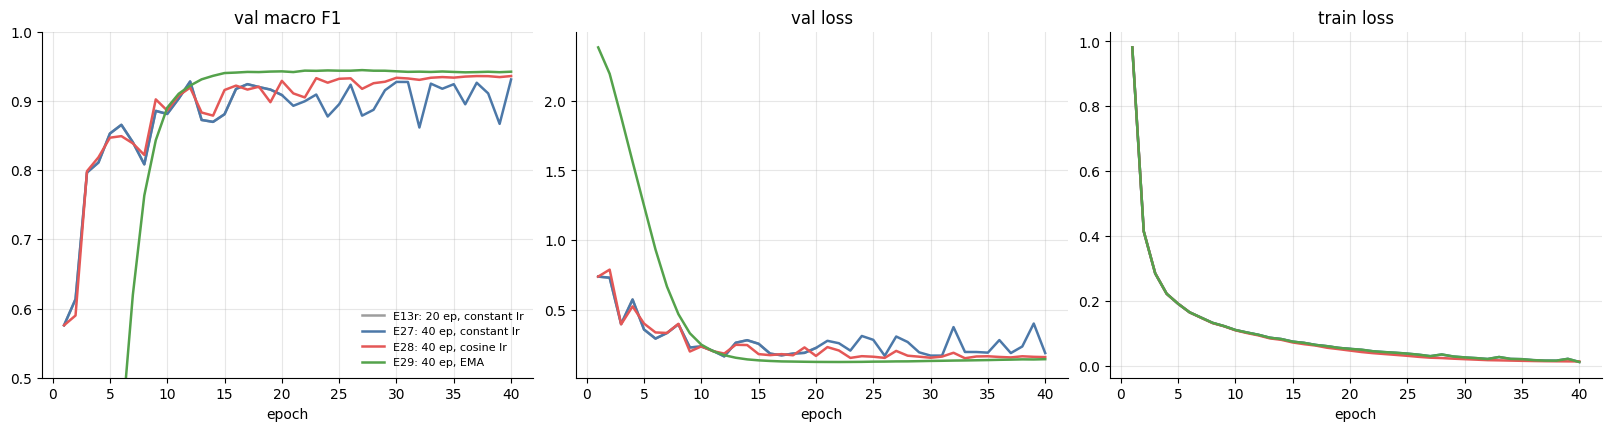

In [13]:
# 셀 8. 학습 곡선 (시드 0): 검증 F1, 검증 손실, 학습 손실
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)
colors = {"E13r": "#9D9D9D", "E27": "#4C78A8", "E28": "#E45756", "E29": "#54A24B"}
names = {"E13r": "E13r: 20 ep, constant lr", "E27": "E27: 40 ep, constant lr", "E28": "E28: 40 ep, cosine lr", "E29": "E29: 40 ep, EMA"}
for r in RUNS:
    if r["시드"] != SEEDS[0]:
        continue
    h = r["hist"]; c = colors[r["번호"]]
    ax[0].plot(h.epoch, h.f1, "-", color=c, lw=1.8, label=names[r["번호"]])
    ax[1].plot(h.epoch, h.val_loss, "-", color=c, lw=1.8)
    ax[2].plot(h.epoch, h.train_loss, "-", color=c, lw=1.8)
ax[0].set_title("val macro F1"); ax[0].set_ylim(0.5, 1.0)
ax[1].set_title("val loss"); ax[2].set_title("train loss")
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=.3); a.spines[["top", "right"]].set_visible(False)
ax[0].legend(frameon=False, fontsize=8)
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/12_stability_curves.png", dpi=150)
plt.show()